# Module 09 — Multivariate Probability

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first, or
keep it open alongside. Every section mirrors a numbered section of the guide. We take a joint table
apart into marginals and conditionals, measure linear dependence with covariance and correlation (and
watch correlation miss a perfectly deterministic relationship), build covariance matrices from scratch,
sample a two-dimensional Gaussian with a hand-made Cholesky factor and draw its ellipses from the
eigendecomposition of $\Sigma$, visualise Gaussian conditioning, verify the law of total variance,
construct Simpson's paradox, and finish with the two famous applications of Gaussian conditioning:
a Kalman filter and Gaussian-process regression.

Everything is plain NumPy first; `scipy.stats` and scikit-learn appear only to confirm the hand computation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. Joint, marginal and conditional distributions — a table taken apart

The joint PMF of (age group, purchases last month) from the guide. Marginalising is summing along an
axis, conditioning is dividing a row (or column) by its sum, and independence means the table equals
the outer product of its marginals:

$$p_X(x) = \sum_y p(x, y), \qquad p(y \mid x) = \frac{p(x, y)}{p_X(x)}, \qquad \text{independent} \iff p(x, y) = p_X(x)\,p_Y(y).$$

In [2]:
ages = ["18-34", "35-54", "55+"]
purchases = ["none", "one", "several"]
J = np.array([[0.20, 0.10, 0.05],
              [0.15, 0.15, 0.10],
              [0.15, 0.07, 0.03]])
print("joint table sums to", J.sum())

p_age = J.sum(axis=1)            # marginal of X: sum out Y (along each row)
p_purch = J.sum(axis=0)          # marginal of Y: sum out X (down each column)
print("P(age)      =", dict(zip(ages, p_age.round(3))))
print("P(purchase) =", dict(zip(purchases, p_purch.round(3))))

cond_Y_given_X = J / p_age[:, None]        # renormalise each row
print("\nP(purchase | age) — every row sums to 1:")
for a, row in zip(ages, cond_Y_given_X):
    print(f"  {a:6s}", dict(zip(purchases, row.round(3))))
cond_X_given_Y = J / p_purch[None, :]      # renormalise each column  (= Bayes' theorem in table form)
print(f"\nP(age = 55+ | several) = {cond_X_given_Y[2, 2]:.4f}   vs the prior P(55+) = {p_age[2]:.2f}")

indep = np.outer(p_age, p_purch)           # what the table would be if age and purchases were independent
print("\ntable under independence (outer product of the marginals):\n", indep.round(3))
print("largest |joint - independent| =", np.abs(J - indep).max().round(3), " -> dependent")
print("rank of the joint table:", np.linalg.matrix_rank(J), "   rank of the independent table:", np.linalg.matrix_rank(indep))

joint table sums to 1.0
P(age)      = {'18-34': np.float64(0.35), '35-54': np.float64(0.4), '55+': np.float64(0.25)}
P(purchase) = {'none': np.float64(0.5), 'one': np.float64(0.32), 'several': np.float64(0.18)}

P(purchase | age) — every row sums to 1:
  18-34  {'none': np.float64(0.571), 'one': np.float64(0.286), 'several': np.float64(0.143)}
  35-54  {'none': np.float64(0.375), 'one': np.float64(0.375), 'several': np.float64(0.25)}
  55+    {'none': np.float64(0.6), 'one': np.float64(0.28), 'several': np.float64(0.12)}

P(age = 55+ | several) = 0.1667   vs the prior P(55+) = 0.25

table under independence (outer product of the marginals):
 [[0.175 0.112 0.063]
 [0.2   0.128 0.072]
 [0.125 0.08  0.045]]
largest |joint - independent| = 0.05  -> dependent
rank of the joint table: 3    rank of the independent table: 1


In [3]:
# conditioning is *filtering*: draw customers from the joint table, keep the 35-54 group, count purchases
n = 100_000
cell = rng.choice(J.size, size=n, p=J.ravel())
age_idx, purch_idx = np.divmod(cell, 3)
keep = age_idx == 1
emp_cond = np.array([(purch_idx[keep] == k).mean() for k in range(3)])
print(f"{keep.sum()} of {n} simulated customers are 35-54  (exact marginal 0.40)")
print("empirical P(purchase | 35-54) by filtering:", emp_cond.round(3), "   exact:", cond_Y_given_X[1].round(3))

40178 of 100000 simulated customers are 35-54  (exact marginal 0.40)
empirical P(purchase | 35-54) by filtering: [0.371 0.379 0.25 ]    exact: [0.375 0.375 0.25 ]


The middle row renormalised by $0.40$ gives $(0.375, 0.375, 0.25)$, exactly what filtering the simulated
customers produces. The outer-product table differs from the joint in every cell (by up to $0.028$), and
it has rank 1 while the real table has rank 3 — a joint table of independent variables is always a rank-1
matrix, because every row is a rescaled copy of the marginal $p_Y$.

**Try it yourself:** replace `J` by `indep` in the conditioning cell — every conditional row should now
equal `p_purch`.

## 2. Covariance and correlation — and what correlation cannot see

$$\operatorname{Cov}(X, Y) = \mathbb{E}[(X - \mu_X)(Y - \mu_Y)], \qquad \rho = \frac{\operatorname{Cov}(X, Y)}{\sigma_X \sigma_Y} \in [-1, 1].$$

Four scatter plots: three Gaussian pairs with different $\rho$, and the pair $Y = X^2$, which is
perfectly dependent yet has correlation zero. Spearman's rank correlation is shown alongside.

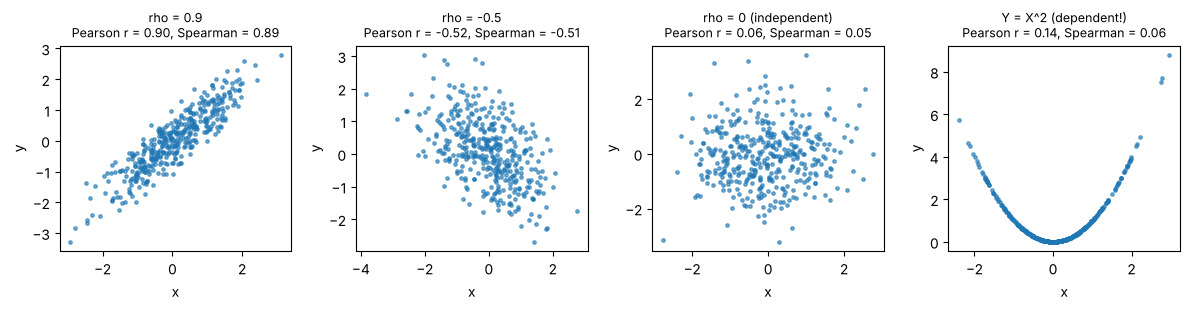

In [4]:
n = 400
def corr_pair(rho, n):
    z = rng.standard_normal((n, 2))
    return z[:, 0], rho * z[:, 0] + np.sqrt(1 - rho**2) * z[:, 1]      # exact correlation rho

cases = [("rho = 0.9", corr_pair(0.9, n)), ("rho = -0.5", corr_pair(-0.5, n)), ("rho = 0 (independent)", corr_pair(0.0, n))]
x = rng.standard_normal(n)
cases.append(("Y = X^2 (dependent!)", (x, x**2)))

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (name, (x, y)) in zip(axes, cases):
    r, rs = np.corrcoef(x, y)[0, 1], stats.spearmanr(x, y)[0]
    ax.scatter(x, y, s=6, alpha=0.6)
    ax.set_title(f"{name}\nPearson r = {r:.2f}, Spearman = {rs:.2f}", fontsize=9)
    ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

In [5]:
# the guide's height/weight example, step by step
h = np.array([160, 165, 170, 175, 180.]); w = np.array([55, 62, 66, 70, 82.])
dh, dw = h - h.mean(), w - w.mean()
print("deviations  h:", dh, "  w:", dw)
print("products   :", dh * dw, "  sum =", (dh * dw).sum())
cov_hw = (dh * dw).sum() / (len(h) - 1)
r_hw = (dh * dw).sum() / np.sqrt((dh**2).sum() * (dw**2).sum())
print(f"sample covariance = {cov_hw:.2f} cm*kg    correlation = {r_hw:.4f}    np.corrcoef gives {np.corrcoef(h, w)[0, 1]:.4f}")
print(f"measured in metres and grams: covariance = {np.cov(h/100, w*1000)[0, 1]:.2f}  but correlation = {np.corrcoef(h/100, w*1000)[0, 1]:.4f}")

# zero correlation without independence, exactly
X = np.array([-1, 0, 1]); Y = X**2
print(f"\nX uniform on {{-1, 0, 1}}, Y = X^2:   E[XY] = {np.mean(X*Y):.3f}   E[X]E[Y] = {X.mean()*Y.mean():.3f}   -> Cov(X, Y) = 0")
print(f"but P(X=1, Y=1) = 1/3 = {1/3:.3f}   while   P(X=1) P(Y=1) = {(1/3)*(2/3):.3f}   -> dependent")

# bilinearity checked by simulation
A = rng.standard_normal(50_000); B = rng.standard_normal(50_000); C = 0.5*A + rng.standard_normal(50_000)
lhs = np.cov(2*A + 3*B, C)[0, 1]; rhs = 2*np.cov(A, C)[0, 1] + 3*np.cov(B, C)[0, 1]
print(f"\nbilinearity: Cov(2A + 3B, C) = {lhs:.4f}    2 Cov(A, C) + 3 Cov(B, C) = {rhs:.4f}")
print(f"Var(A + C) = {np.var(A + C, ddof=1):.4f}    Var A + Var C + 2 Cov = {np.var(A, ddof=1) + np.var(C, ddof=1) + 2*np.cov(A, C)[0, 1]:.4f}")

deviations  h: [-10.  -5.   0.   5.  10.]   w: [-12.  -5.  -1.   3.  15.]
products   : [120.  25.  -0.  15. 150.]   sum = 310.0
sample covariance = 77.50 cm*kg    correlation = 0.9754    np.corrcoef gives 0.9754
measured in metres and grams: covariance = 775.00  but correlation = 0.9754

X uniform on {-1, 0, 1}, Y = X^2:   E[XY] = 0.000   E[X]E[Y] = 0.000   -> Cov(X, Y) = 0
but P(X=1, Y=1) = 1/3 = 0.333   while   P(X=1) P(Y=1) = 0.222   -> dependent

bilinearity: Cov(2A + 3B, C) = 1.0013    2 Cov(A, C) + 3 Cov(B, C) = 1.0013
Var(A + C) = 3.2654    Var A + Var C + 2 Cov = 3.2654


The fourth panel is the point of the section: $Y$ is a deterministic function of $X$, yet Pearson's $r$
and even Spearman's rank correlation are both about zero, because the relationship is neither linear nor
monotone. Correlation measures how well a *straight line* describes the cloud, nothing more. Covariance
changes with the units (77.5 cm·kg becomes 775 m·g); correlation does not — it is the covariance of the
standardised variables.

**Try it yourself:** in `corr_pair`, generate $y = \sin(3x)$ plus a little noise and look at Pearson vs
Spearman; then try $y = e^{x}$, which is monotone — Spearman should jump to 1 while Pearson stays below.

## 3. Random vectors and covariance matrices

$$\Sigma = \mathbb{E}\big[(X - \mu)(X - \mu)^\top\big], \qquad \operatorname{Var}(a^\top X) = a^\top \Sigma a \ge 0, \qquad S = \frac{1}{n-1}\mathbf{X}_c^\top \mathbf{X}_c .$$

We generate 2,000 observations of three correlated "asset returns", build the sample covariance from the
centred data matrix, and compare with `np.cov`. Then the three-asset portfolio of the guide, a
positive-semidefiniteness check, and whitening.

In [6]:
sd = np.array([0.20, 0.10, 0.30])                              # volatilities of three assets
R = np.array([[1.0, 0.3, 0.5],
              [0.3, 1.0, 0.0],
              [0.5, 0.0, 1.0]])                                # correlation matrix
Sigma_true = np.outer(sd, sd) * R                              # Sigma_ij = rho_ij sigma_i sigma_j
mu_true = np.array([0.08, 0.03, 0.10])
X = rng.multivariate_normal(mu_true, Sigma_true, size=2000)    # rows = observations, columns = variables

Xc = X - X.mean(axis=0)                                        # centre every column
S = Xc.T @ Xc / (len(X) - 1)                                   # sample covariance, from scratch
print("sample covariance S (from scratch):\n", S.round(4))
print("np.cov(X, rowvar=False):\n", np.cov(X, rowvar=False).round(4))
print("largest difference:", np.abs(S - np.cov(X, rowvar=False)).max())
print("true Sigma:\n", Sigma_true.round(4))
print("\nsample correlation matrix (D^-1/2 S D^-1/2):\n", (S / np.sqrt(np.outer(np.diag(S), np.diag(S)))).round(3))

sample covariance S (from scratch):
 [[ 0.0416  0.007   0.0285]
 [ 0.007   0.0108 -0.0005]
 [ 0.0285 -0.0005  0.0885]]
np.cov(X, rowvar=False):
 [[ 0.0416  0.007   0.0285]
 [ 0.007   0.0108 -0.0005]
 [ 0.0285 -0.0005  0.0885]]
largest difference: 1.3877787807814457e-17
true Sigma:
 [[0.04  0.006 0.03 ]
 [0.006 0.01  0.   ]
 [0.03  0.    0.09 ]]

sample correlation matrix (D^-1/2 S D^-1/2):
 [[ 1.     0.33   0.47 ]
 [ 0.33   1.    -0.017]
 [ 0.47  -0.017  1.   ]]


In [7]:
w = np.array([0.5, 0.3, 0.2])                                  # portfolio weights
print("Sigma w =", (Sigma_true @ w).round(4))
var_p = w @ Sigma_true @ w
print(f"portfolio variance w'Sigma w = {var_p:.4f}   volatility = {np.sqrt(var_p):.4f}")
print(f"weighted average of the volatilities = {w @ sd:.4f};  if the assets were uncorrelated: {np.sqrt(w**2 @ sd**2):.4f}")
print(f"empirical variance of the simulated portfolio returns X w: {np.var(X @ w, ddof=1):.4f}   vs  w'S w = {w @ S @ w:.4f}")

# a covariance matrix is positive semidefinite: a'Sigma a = Var(a'X) >= 0 for *every* a
print("\neigenvalues of Sigma:", np.linalg.eigvalsh(Sigma_true).round(4), "  all >= 0")
dirs = rng.standard_normal((5000, 3))
quad = np.einsum("ij,jk,ik->i", dirs, Sigma_true, dirs)        # a'Sigma a for 5000 random directions
print(f"smallest a'Sigma a over 5000 random directions: {quad.min():.6f}")
bad = np.array([[1.0, 0.9, 0.9], [0.9, 1.0, -0.9], [0.9, -0.9, 1.0]])
print("eigenvalues of an impossible 'correlation matrix' (rho12 = rho13 = 0.9, rho23 = -0.9):", np.linalg.eigvalsh(bad).round(3))
a = np.array([0, 1, 1.0]); print(f"  it would give Var(X2 + X3) = a'Ra = {a @ bad @ a:.2f} < 0")

# crisis scenario: all correlations rise to 0.8
Sigma_crisis = np.outer(sd, sd) * np.where(np.eye(3) == 1, 1.0, 0.8)
print(f"\ncrisis (all rho = 0.8): volatility = {np.sqrt(w @ Sigma_crisis @ w):.4f}   diversification benefit shrinks from "
      f"{w @ sd - np.sqrt(var_p):.4f} to {w @ sd - np.sqrt(w @ Sigma_crisis @ w):.4f}")

Sigma w = [0.0278 0.006  0.033 ]
portfolio variance w'Sigma w = 0.0223   volatility = 0.1493
weighted average of the volatilities = 0.1900;  if the assets were uncorrelated: 0.1204
empirical variance of the simulated portfolio returns X w: 0.0227   vs  w'S w = 0.0227

eigenvalues of Sigma: [0.0083 0.0276 0.1041]   all >= 0
smallest a'Sigma a over 5000 random directions: 0.000054
eigenvalues of an impossible 'correlation matrix' (rho12 = rho13 = 0.9, rho23 = -0.9): [-0.8  1.9  1.9]
  it would give Var(X2 + X3) = a'Ra = 0.20 < 0

crisis (all rho = 0.8): volatility = 0.1783   diversification benefit shrinks from 0.0407 to 0.0117


covariance of the whitened data:
 [[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]


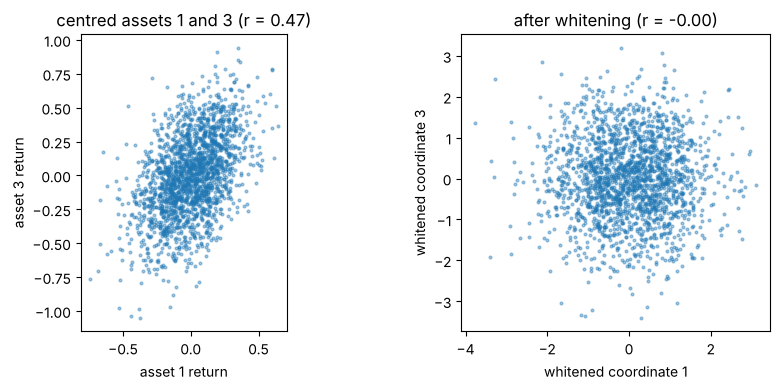

In [8]:
# whitening: Z = Sigma^{-1/2} (X - mu) has identity covariance
lam, U = np.linalg.eigh(S)
W = U @ np.diag(lam ** -0.5) @ U.T                             # symmetric inverse square root S^{-1/2}
Z = Xc @ W.T
print("covariance of the whitened data:\n", np.cov(Z, rowvar=False).round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ax1.scatter(Xc[:, 0], Xc[:, 2], s=4, alpha=0.4)
ax1.set_title(f"centred assets 1 and 3 (r = {np.corrcoef(X[:, 0], X[:, 2])[0, 1]:.2f})"); ax1.set_xlabel("asset 1 return"); ax1.set_ylabel("asset 3 return"); ax1.set_aspect("equal")
ax2.scatter(Z[:, 0], Z[:, 2], s=4, alpha=0.4)
ax2.set_title(f"after whitening (r = {np.corrcoef(Z[:, 0], Z[:, 2])[0, 1]:.2f})"); ax2.set_xlabel("whitened coordinate 1"); ax2.set_ylabel("whitened coordinate 3"); ax2.set_aspect("equal")
plt.tight_layout(); plt.show()

The from-scratch $S$ matches `np.cov(X, rowvar=False)` to machine precision (remember: `rowvar=False` or
`np.cov(X.T)` — NumPy's default treats *rows* as variables). The portfolio volatility, $14.9\%$, lies
between the uncorrelated value ($12.0\%$) and the weighted average ($19\%$); the two positive correlations
cost almost three points, and in the crisis scenario the benefit of diversifying nearly vanishes. The
"correlation matrix" with $0.9, 0.9, -0.9$ has a negative eigenvalue and would assign a *negative variance*
to $X_2 + X_3$ — it cannot describe any random vector. Whitening by $S^{-1/2}$ turns the tilted cloud into
a round one with identity covariance.

**Try it yourself:** set `size=4` in the sampling call and look at `np.linalg.eigvalsh(S)` — with fewer
observations than dimensions plus one, the sample covariance is singular (an eigenvalue of zero).

## 4. The multivariate Gaussian: Cholesky sampling and the geometry of $\Sigma$

$$f(x) = \frac{1}{(2\pi)^{d/2}|\Sigma|^{1/2}} \exp\!\Big(-\tfrac12 (x-\mu)^\top \Sigma^{-1} (x-\mu)\Big), \qquad X = \mu + L z \sim \mathcal{N}(\mu, LL^\top).$$

For $\Sigma = \begin{pmatrix} 2 & 1 \\ 1 & 1\end{pmatrix}$ we compute the Cholesky factor by hand, draw
4,000 samples, and overlay the ellipses $\Delta^2 = 1, 4, 5.99$ whose axes are the eigenvectors of $\Sigma$
scaled by $\sqrt{c\lambda_i}$.

L by hand:
 [[1.4142 0.    ]
 [0.7071 0.7071]] 
np.linalg.cholesky:
 [[1.4142 0.    ]
 [0.7071 0.7071]]
L L^T =
 [[2. 1.]
 [1. 1.]]

sample mean: [0.004 0.022]    sample covariance:
 [[1.973 0.964]
 [0.964 0.973]]

eigenvalues: [0.382 2.618]   = (3 -/+ sqrt5)/2 = 0.3820, 2.6180
major axis direction [0.851 0.526] at 31.7 degrees;  1-sd semi-axes = sqrt(lambda) = [0.618 1.618]


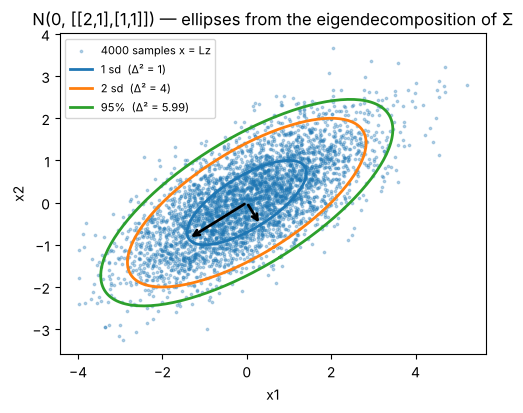

fraction of samples inside the 95% ellipse: 0.951   (Δ² ~ chi-square with 2 degrees of freedom)


In [9]:
Sigma = np.array([[2.0, 1.0], [1.0, 1.0]])
a, b, c = Sigma[0, 0], Sigma[0, 1], Sigma[1, 1]
L = np.array([[np.sqrt(a), 0.0],
              [b / np.sqrt(a), np.sqrt(c - b**2 / a)]])     # Cholesky of a 2x2 matrix, by hand
print("L by hand:\n", L.round(4), "\nnp.linalg.cholesky:\n", np.linalg.cholesky(Sigma).round(4))
print("L L^T =\n", L @ L.T)

z = rng.standard_normal((4000, 2))
X2 = z @ L.T                                                   # every row is x = L z   (mu = 0)
print("\nsample mean:", X2.mean(axis=0).round(3), "   sample covariance:\n", np.cov(X2, rowvar=False).round(3))

lam, U = np.linalg.eigh(Sigma)                                 # eigenvalues ascending
u_major = U[:, 1] * np.sign(U[0, 1])                           # fix the arbitrary sign
print(f"\neigenvalues: {lam.round(4)}   = (3 -/+ sqrt5)/2 = {((3 - np.sqrt(5))/2):.4f}, {((3 + np.sqrt(5))/2):.4f}")
print(f"major axis direction {u_major.round(3)} at {np.degrees(np.arctan2(u_major[1], u_major[0])):.1f} degrees;  1-sd semi-axes = sqrt(lambda) = {np.sqrt(lam).round(3)}")

def ellipse(mu, Sigma, c, n_pts=200):
    # points x with (x - mu)' Sigma^{-1} (x - mu) = c:  the unit circle mapped by U diag(sqrt(c lambda))
    lam, U = np.linalg.eigh(Sigma)
    t = np.linspace(0, 2*np.pi, n_pts)
    return mu[:, None] + U @ np.diag(np.sqrt(c * lam)) @ np.stack([np.cos(t), np.sin(t)])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(X2[:, 0], X2[:, 1], s=3, alpha=0.3, label="4000 samples x = Lz")
for cval, lab in [(1.0, "1 sd  (Δ² = 1)"), (4.0, "2 sd  (Δ² = 4)"), (stats.chi2.ppf(0.95, 2), "95%  (Δ² = 5.99)")]:
    e = ellipse(np.zeros(2), Sigma, cval); ax.plot(e[0], e[1], lw=2, label=lab)
for i in range(2):
    ax.annotate("", xy=tuple(np.sqrt(lam[i]) * U[:, i]), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k", lw=2))
ax.set_aspect("equal"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("N(0, [[2,1],[1,1]]) — ellipses from the eigendecomposition of Σ"); plt.show()

d2 = np.einsum("ij,jk,ik->i", X2, np.linalg.inv(Sigma), X2)    # squared Mahalanobis distance of every sample
print(f"fraction of samples inside the 95% ellipse: {(d2 <= stats.chi2.ppf(0.95, 2)).mean():.3f}   (Δ² ~ chi-square with 2 degrees of freedom)")

In [10]:
def mvn_logpdf(x, mu, Sigma):
    # log density via the Cholesky factor: never invert Sigma explicitly
    L = np.linalg.cholesky(Sigma)
    y = np.linalg.solve(L, x - mu)                 # L^{-1}(x - mu); then y'y = (x-mu)' Sigma^{-1} (x-mu)
    log_det = 2.0 * np.log(np.diag(L)).sum()       # log|Sigma| = 2 sum_i log L_ii
    return -0.5 * (len(mu) * np.log(2 * np.pi) + log_det + y @ y)

ref = stats.multivariate_normal(np.zeros(2), Sigma)
for x in (np.array([1.0, 1.0]), np.array([1.0, -1.0]), np.zeros(2)):
    print(f"x = {x}:  Mahalanobis^2 = {x @ np.linalg.inv(Sigma) @ x:.1f}   density = {np.exp(mvn_logpdf(x, np.zeros(2), Sigma)):.4f}   scipy: {ref.pdf(x):.4f}")
ratio = np.exp(mvn_logpdf(np.array([1.0, 1.0]), np.zeros(2), Sigma) - mvn_logpdf(np.array([1.0, -1.0]), np.zeros(2), Sigma))
print(f"f(1, 1) / f(1, -1) = {ratio:.3f} = e^2:  same Euclidean length, very different probability")

x = [1. 1.]:  Mahalanobis^2 = 1.0   density = 0.0965   scipy: 0.0965
x = [ 1. -1.]:  Mahalanobis^2 = 5.0   density = 0.0131   scipy: 0.0131
x = [0. 0.]:  Mahalanobis^2 = 0.0   density = 0.1592   scipy: 0.1592
f(1, 1) / f(1, -1) = 7.389 = e^2:  same Euclidean length, very different probability


Roughly 95% of the samples fall inside the $\Delta^2 = 5.99$ ellipse, as the $\chi^2_2$ law predicts. The
arrows are the eigenvectors scaled by $\sqrt{\lambda_i}$: the long axis points along $(0.85, 0.53)$ because
the correlation is positive, and the ratio of the semi-axes is $\sqrt{2.618/0.382} = 2.6$. The two points
$(1, 1)$ and $(1, -1)$ are equally far from the origin in Euclidean terms, but one lies along the cloud and
the other across it — the Mahalanobis distances $1$ and $5$ (hence densities differing by $e^2$) are what the
Gaussian actually sees.

**Try it yourself:** change the off-diagonal of `Sigma` to $-1$ and re-run; then to $1.4$ — what happens to
the Cholesky factor when $\Sigma$ stops being positive definite?

## 5. Marginalisation and conditioning in Gaussians

$$\mu_{1|2} = \mu_1 + \Sigma_{12}\Sigma_{22}^{-1}(x_2 - \mu_2), \qquad \Sigma_{1|2} = \Sigma_{11} - \Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}.$$

We implement the formula for any split of the coordinates, apply it to $\Sigma = \begin{pmatrix} 2 & 1 \\ 1 & 1\end{pmatrix}$,
and check it against brute force: filter 200,000 samples to those with $x_2 \approx 1.5$ and look at their $x_1$.

In [11]:
def gaussian_condition(mu, Sigma, obs_idx, obs_val):
    # distribution of the remaining coordinates given X[obs_idx] = obs_val
    mu = np.asarray(mu, float); Sigma = np.asarray(Sigma, float)
    obs_idx = list(obs_idx); free = [i for i in range(len(mu)) if i not in obs_idx]
    S11 = Sigma[np.ix_(free, free)]; S12 = Sigma[np.ix_(free, obs_idx)]; S22 = Sigma[np.ix_(obs_idx, obs_idx)]
    gain = S12 @ np.linalg.inv(S22)                            # Sigma_12 Sigma_22^{-1}: the regression coefficients
    mu_c = mu[free] + gain @ (np.asarray(obs_val, float) - mu[obs_idx])
    Sigma_c = S11 - gain @ S12.T                               # Schur complement
    return mu_c, Sigma_c

mu_c, S_c = gaussian_condition(np.zeros(2), Sigma, [1], [1.5])
print(f"X1 | X2 = 1.5  ~  N({mu_c[0]:.3f}, {S_c[0, 0]:.3f})       marginal of X1 is N(0, 2)")
mu_c2, S_c2 = gaussian_condition(np.zeros(2), Sigma, [0], [2.0])
print(f"X2 | X1 = 2.0  ~  N({mu_c2[0]:.3f}, {S_c2[0, 0]:.3f})       marginal of X2 is N(0, 1)")
print(f"both variances shrink by the factor 1 - rho^2 = {1 - Sigma[0, 1]**2 / (Sigma[0, 0] * Sigma[1, 1]):.3f}")

Xbig = rng.standard_normal((200_000, 2)) @ L.T
band = np.abs(Xbig[:, 1] - 1.5) < 0.05                        # brute force: keep samples with x2 close to 1.5
print(f"\n{band.sum()} samples have x2 within 1.5 +/- 0.05:  mean of x1 = {Xbig[band, 0].mean():.3f},  variance = {Xbig[band, 0].var():.3f}")
far = np.abs(Xbig[:, 1] - 3.0) < 0.05                         # an extreme observation: same variance, shifted mean
print(f"{far.sum()} samples have x2 within 3.0 +/- 0.05:  mean of x1 = {Xbig[far, 0].mean():.3f},  variance = {Xbig[far, 0].var():.3f}   (formula: 3.0, 1.0)")

X1 | X2 = 1.5  ~  N(1.500, 1.000)       marginal of X1 is N(0, 2)
X2 | X1 = 2.0  ~  N(1.000, 0.500)       marginal of X2 is N(0, 1)
both variances shrink by the factor 1 - rho^2 = 0.500



2595 samples have x2 within 1.5 +/- 0.05:  mean of x1 = 1.484,  variance = 0.978
107 samples have x2 within 3.0 +/- 0.05:  mean of x1 = 2.995,  variance = 0.975   (formula: 3.0, 1.0)


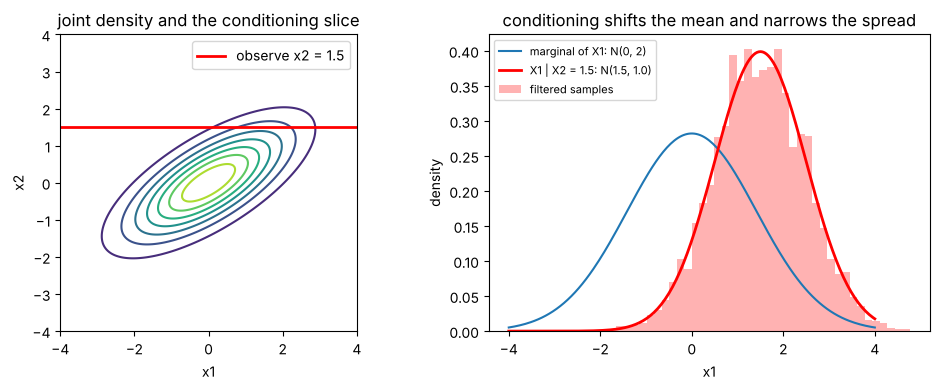

In [12]:
g = np.linspace(-4, 4, 200); G1, G2 = np.meshgrid(g, g)
dens = ref.pdf(np.stack([G1.ravel(), G2.ravel()], axis=1)).reshape(G1.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.contour(G1, G2, dens, levels=8)
ax1.axhline(1.5, color="r", lw=2, label="observe x2 = 1.5")
ax1.set_xlabel("x1"); ax1.set_ylabel("x2"); ax1.set_title("joint density and the conditioning slice"); ax1.legend(); ax1.set_aspect("equal")
ax2.plot(g, stats.norm.pdf(g, 0, np.sqrt(2)), label="marginal of X1: N(0, 2)")
ax2.plot(g, stats.norm.pdf(g, mu_c[0], np.sqrt(S_c[0, 0])), "r", lw=2, label=f"X1 | X2 = 1.5: N({mu_c[0]:.1f}, {S_c[0, 0]:.1f})")
ax2.hist(Xbig[band, 0], bins=40, density=True, alpha=0.3, color="r", label="filtered samples")
ax2.set_xlabel("x1"); ax2.set_ylabel("density"); ax2.set_title("conditioning shifts the mean and narrows the spread"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [13]:
# height (cm) and weight (kg): mean (170, 70), sds (10, 12), correlation 0.6
mu_hw = np.array([170.0, 70.0]); S_hw = np.array([[100.0, 72.0], [72.0, 144.0]])
for h_obs in (155, 170, 185):
    m, v = gaussian_condition(mu_hw, S_hw, [0], [h_obs])
    print(f"height {h_obs} cm  ->  weight ~ N({m[0]:.1f}, sd {np.sqrt(v[0, 0]):.2f})")
m, v = gaussian_condition(mu_hw, S_hw, [1], [90.0])
print(f"weight 90 kg   ->  height ~ N({m[0]:.1f}, sd {np.sqrt(v[0, 0]):.2f})")
slope_w_on_h = S_hw[0, 1] / S_hw[0, 0]; slope_h_on_w = S_hw[0, 1] / S_hw[1, 1]
print(f"\nregression slopes: weight on height {slope_w_on_h:.2f} kg/cm,  height on weight {slope_h_on_w:.2f} cm/kg,  product = {slope_w_on_h * slope_h_on_w:.2f} = rho^2 (not 1)")

height 155 cm  ->  weight ~ N(59.2, sd 9.60)
height 170 cm  ->  weight ~ N(70.0, sd 9.60)
height 185 cm  ->  weight ~ N(80.8, sd 9.60)
weight 90 kg   ->  height ~ N(180.0, sd 8.00)

regression slopes: weight on height 0.72 kg/cm,  height on weight 0.50 cm/kg,  product = 0.36 = rho^2 (not 1)


The filtered samples near $x_2 = 1.5$ have mean $\approx 1.5$ and variance $\approx 1$ — half the marginal
variance of 2 — and the samples near the much rarer $x_2 = 3$ have the *same* variance with a shifted mean:
in a Gaussian the conditional covariance never depends on the observed value. In the plot the red
conditional is both displaced and narrower than the blue marginal. The height/weight numbers show
regression to the mean: a person $1.5$ standard deviations tall is predicted to be only $0.9$ standard
deviations heavy, and the two regression slopes multiply to $\rho^2 = 0.36$, so you cannot invert one
regression line to get the other.

## 6. Conditional expectation and the law of total variance

$$\operatorname{Var}(Y) = \mathbb{E}\big[\operatorname{Var}(Y \mid X)\big] + \operatorname{Var}\big(\mathbb{E}[Y \mid X]\big), \qquad
\mathbb{E}[Y \mid X] = \arg\min_g \mathbb{E}\big[(Y - g(X))^2\big].$$

First the insurer's two segments from the guide (60% with $\mathcal{N}(10, 4)$, 40% with $\mathcal{N}(20, 9)$):
the within and between parts should sum to $6 + 24 = 30$. Then a nonlinear regression function, where we
compare the mean squared error of several predictors with the true $\mathbb{E}[Y \mid X]$.

In [14]:
n = 200_000
in_B = rng.random(n) < 0.4                                     # segment B with probability 0.4
Y = np.where(in_B, rng.normal(20, 3, n), rng.normal(10, 2, n))
cond_mean = np.where(in_B, 20.0, 10.0)                         # E[Y | X] as a random variable
cond_var = np.where(in_B, 9.0, 4.0)                            # Var(Y | X) as a random variable
print(f"Var(Y) by simulation            = {Y.var():.3f}")
print(f"E[Var(Y|X)] (within)            = {cond_var.mean():.3f}     exact 0.6*4 + 0.4*9 = 6")
print(f"Var(E[Y|X]) (between)           = {cond_mean.var():.3f}    exact 0.6*16 + 0.4*36 = 24")
print(f"within + between                = {cond_var.mean() + cond_mean.var():.3f}")
print(f"tower property: E[E[Y|X]] = {cond_mean.mean():.3f} = E[Y] = {Y.mean():.3f}")
print(f"fraction of variance explained by the segment: {cond_mean.var() / Y.var():.3f}")

# Gaussian check: for Sigma = [[2,1],[1,1]], Var(X1|X2) = 1 and Var(E[X1|X2]) = Var(X2) = 1, summing to Sigma_11 = 2
print(f"\nGaussian: E[Var(X1|X2)] + Var(E[X1|X2]) = {S_c[0, 0]:.1f} + {Sigma[1, 1]:.1f} = {S_c[0, 0] + Sigma[1, 1]:.1f} = Sigma_11")

Var(Y) by simulation            = 29.933
E[Var(Y|X)] (within)            = 5.993     exact 0.6*4 + 0.4*9 = 6
Var(E[Y|X]) (between)           = 23.971    exact 0.6*16 + 0.4*36 = 24
within + between                = 29.964
tower property: E[E[Y|X]] = 13.986 = E[Y] = 13.998
fraction of variance explained by the segment: 0.801

Gaussian: E[Var(X1|X2)] + Var(E[X1|X2]) = 1.0 + 1.0 = 2.0 = Sigma_11


constant E[Y]        MSE = 0.8154
best straight line   MSE = 0.4532
cubic polynomial     MSE = 0.1659
true E[Y | X]        MSE = 0.1617
noise floor          E[Var(Y|X)] = 0.4^2 = 0.1600


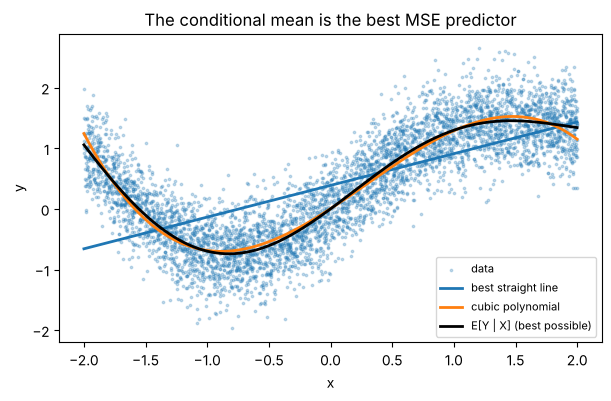

In [15]:
n = 5000
x = rng.uniform(-2, 2, n)
m_true = np.sin(1.5 * x) + 0.3 * x**2                          # the regression function E[Y | X = x]
y = m_true + rng.normal(0, 0.4, n)                             # Var(Y | X) = 0.16, the noise floor

predictors = {"constant E[Y]": np.full(n, y.mean()),
              "best straight line": np.polyval(np.polyfit(x, y, 1), x),
              "cubic polynomial": np.polyval(np.polyfit(x, y, 3), x),
              "true E[Y | X]": m_true}
for name, pred in predictors.items():
    print(f"{name:20s} MSE = {np.mean((y - pred)**2):.4f}")
print(f"{'noise floor':20s} E[Var(Y|X)] = 0.4^2 = {0.16:.4f}")

order = np.argsort(x)
plt.scatter(x, y, s=3, alpha=0.25, label="data")
plt.plot(x[order], predictors["best straight line"][order], lw=2, label="best straight line")
plt.plot(x[order], predictors["cubic polynomial"][order], lw=2, label="cubic polynomial")
plt.plot(x[order], m_true[order], "k", lw=2, label="E[Y | X] (best possible)")
plt.xlabel("x"); plt.ylabel("y"); plt.title("The conditional mean is the best MSE predictor"); plt.legend(fontsize=8); plt.show()

Within plus between reproduces the total variance, and the segment explains $24/30 = 80\%$ of it. In the
second experiment no predictor beats the true conditional mean, whose MSE sits at the noise floor
$\mathbb{E}[\operatorname{Var}(Y \mid X)] = 0.16$; the straight line is far above it because
$\mathbb{E}[Y \mid X]$ is not linear here. Every regressor you will ever train is trying to approximate the
black curve — and no amount of data or model capacity gets it below $0.16$.

**Try it yourself:** increase the noise standard deviation from $0.4$ to $1.0$ and watch the gap between
the straight line and the truth shrink *relative* to the noise floor — when is a linear model "good enough"?

## 7. Simpson's paradox

$$P(R \mid T) = \sum_s P(R \mid T, s)\,P(s \mid T):$$

the aggregate rate mixes the stratum rates with each treatment's *own* severity mix. We reproduce the
guide's table, then build a continuous version: three age groups in which the within-group trend is
negative while the overall trend is positive.

In [16]:
import pandas as pd
rows = [("A", "mild", 20, 18), ("A", "severe", 80, 48), ("B", "mild", 80, 68), ("B", "severe", 20, 10)]
df = pd.DataFrame(rows, columns=["treatment", "severity", "patients", "recovered"])
df["rate"] = df.recovered / df.patients
strat = df.pivot(index="treatment", columns="severity", values="rate")[["mild", "severe"]]
print("recovery rate within each severity stratum:\n", strat.round(3))

agg = df.groupby("treatment")[["patients", "recovered"]].sum()
agg["rate"] = agg.recovered / agg.patients
print("\naggregate recovery rate:\n", agg)

mix = df.pivot(index="treatment", columns="severity", values="patients")[["mild", "severe"]]
mix = mix.div(mix.sum(axis=1), axis=0)
print("\nseverity mix P(s | T) — the culprit:\n", mix.round(2))

pooled = df.groupby("severity").patients.sum() / df.patients.sum()
standardised = (strat * pooled[strat.columns]).sum(axis=1)
print("\nstandardised rate with the pooled mix (50/50):\n", standardised.round(3))
print("\nA wins in every stratum, B wins overall: P(R|A) = 0.9*0.2 + 0.6*0.8 =", round(0.9*0.2 + 0.6*0.8, 2),
      "  P(R|B) = 0.85*0.8 + 0.5*0.2 =", round(0.85*0.8 + 0.5*0.2, 2))

recovery rate within each severity stratum:
 severity   mild  severe
treatment              
A          0.90     0.6
B          0.85     0.5

aggregate recovery rate:
            patients  recovered  rate
treatment                           
A               100         66  0.66
B               100         78  0.78

severity mix P(s | T) — the culprit:
 severity   mild  severe
treatment              
A           0.2     0.8
B           0.8     0.2

standardised rate with the pooled mix (50/50):
 treatment
A    0.750
B    0.675
dtype: float64

A wins in every stratum, B wins overall: P(R|A) = 0.9*0.2 + 0.6*0.8 = 0.66   P(R|B) = 0.85*0.8 + 0.5*0.2 = 0.78


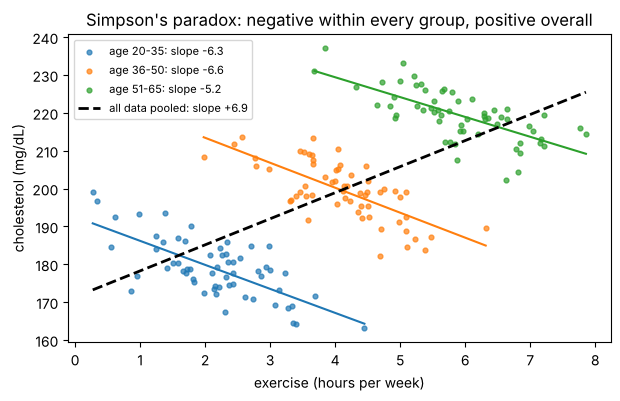

pooled correlation = +0.67;  within-group correlations are all negative


In [17]:
# continuous Simpson: weekly exercise hours vs cholesterol, three age groups
groups = {"age 20-35": (2.0, 180.0), "age 36-50": (4.0, 200.0), "age 51-65": (6.0, 220.0)}
all_x, all_y = [], []
for name, (mx, my) in groups.items():
    xg = mx + rng.normal(0, 0.8, 60)
    yg = my - 6.0 * (xg - mx) + rng.normal(0, 5, 60)           # within each group: more exercise, lower cholesterol
    slope = np.polyfit(xg, yg, 1)[0]
    plt.scatter(xg, yg, s=12, alpha=0.7, label=f"{name}: slope {slope:+.1f}")
    xs_ = np.linspace(xg.min(), xg.max(), 2); plt.plot(xs_, np.polyval(np.polyfit(xg, yg, 1), xs_), lw=1.5)
    all_x.append(xg); all_y.append(yg)
all_x, all_y = np.concatenate(all_x), np.concatenate(all_y)
coef = np.polyfit(all_x, all_y, 1)
xs_ = np.linspace(all_x.min(), all_x.max(), 2)
plt.plot(xs_, np.polyval(coef, xs_), "k--", lw=2, label=f"all data pooled: slope {coef[0]:+.1f}")
plt.xlabel("exercise (hours per week)"); plt.ylabel("cholesterol (mg/dL)")
plt.title("Simpson's paradox: negative within every group, positive overall"); plt.legend(fontsize=8); plt.show()
print(f"pooled correlation = {np.corrcoef(all_x, all_y)[0, 1]:+.2f};  within-group correlations are all negative")

In the table, A beats B in both strata (90% vs 85%, 60% vs 50%) and loses overall (66% vs 78%) because 80%
of A's patients were severe against 20% of B's. Standardising both treatments to the same 50/50 mix restores
the stratified verdict. In the scatter plot the confounder is age: older people exercise more *and* have
higher cholesterol in this (synthetic) population, so pooling the groups produces a positive slope even
though exercise lowers cholesterol within every group. Which analysis is right is a causal question — here
age is a confounder, so the within-group slopes are the ones to believe.

## 8a. A one-dimensional Kalman filter

Hidden position $x_t = x_{t-1} + v + w_t$, $w_t \sim \mathcal{N}(0, q)$; measurement $z_t = x_t + r_t$, $r_t \sim \mathcal{N}(0, r)$.

$$\text{predict: } \mu^- = \mu + v,\ P^- = P + q; \qquad \text{update: } K = \frac{P^-}{P^- + r},\ \mu = \mu^- + K(z_t - \mu^-),\ P = (1 - K)P^- .$$

We track an object for 60 steps with $v = 1$, $q = 1$, $r = 3$ (the guide's numbers), compare the filter's
error with the raw sensor, and watch the gain converge to its steady state.

RMSE of the raw sensor: 1.463     RMSE of the Kalman estimate: 1.111
filter's own sd at the end: 1.141   steady-state formula sqrt(P- r/(P- + r)) = 1.141   sensor sd = 1.732
gain at the end: 0.4343   steady-state K = P-/(P- + r) = 0.4343


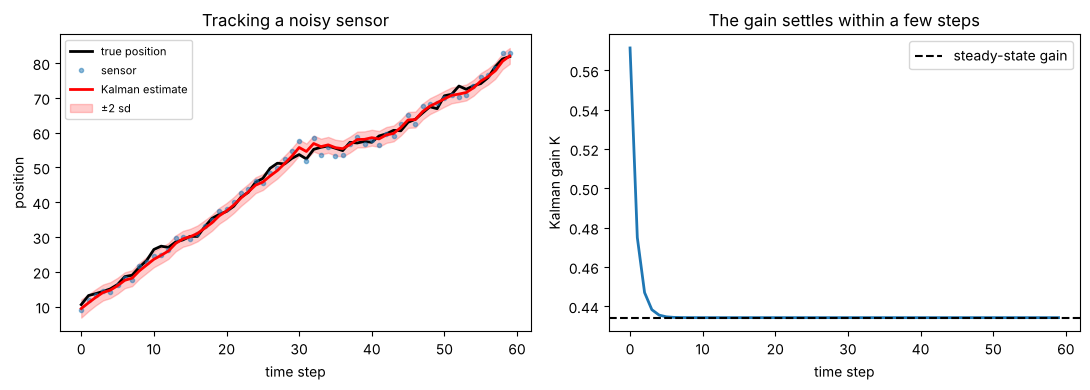

In [18]:
T, v, q, r = 60, 1.0, 1.0, 3.0
x_true = np.empty(T); x_true[0] = 10 + rng.normal(0, 2)
for t in range(1, T):
    x_true[t] = x_true[t - 1] + v + rng.normal(0, np.sqrt(q))
z = x_true + rng.normal(0, np.sqrt(r), T)                      # noisy sensor readings

mu, P = 10.0, 4.0                                              # prior belief about x_0
mus, Ps, Ks = np.empty(T), np.empty(T), np.empty(T)
for t in range(T):
    if t > 0:
        mu, P = mu + v, P + q                                  # predict
    K = P / (P + r)                                            # Kalman gain
    mu, P = mu + K * (z[t] - mu), (1 - K) * P                  # update = Gaussian conditioning
    mus[t], Ps[t], Ks[t] = mu, P, K

rmse = lambda est: np.sqrt(np.mean((est - x_true)**2))
P_minus_inf = (q + np.sqrt(q**2 + 4*q*r)) / 2
print(f"RMSE of the raw sensor: {rmse(z):.3f}     RMSE of the Kalman estimate: {rmse(mus):.3f}")
print(f"filter's own sd at the end: {np.sqrt(Ps[-1]):.3f}   steady-state formula sqrt(P- r/(P- + r)) = {np.sqrt(P_minus_inf * r / (P_minus_inf + r)):.3f}   sensor sd = {np.sqrt(r):.3f}")
print(f"gain at the end: {Ks[-1]:.4f}   steady-state K = P-/(P- + r) = {P_minus_inf / (P_minus_inf + r):.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(x_true, "k", lw=2, label="true position")
ax1.plot(z, "o", ms=3, alpha=0.5, label="sensor")
ax1.plot(mus, "r", lw=2, label="Kalman estimate")
ax1.fill_between(np.arange(T), mus - 2*np.sqrt(Ps), mus + 2*np.sqrt(Ps), color="r", alpha=0.2, label="±2 sd")
ax1.set_xlabel("time step"); ax1.set_ylabel("position"); ax1.set_title("Tracking a noisy sensor"); ax1.legend(fontsize=8)
ax2.plot(Ks, lw=2); ax2.axhline(P_minus_inf / (P_minus_inf + r), color="k", ls="--", label="steady-state gain")
ax2.set_xlabel("time step"); ax2.set_ylabel("Kalman gain K"); ax2.set_title("The gain settles within a few steps"); ax2.legend()
plt.tight_layout(); plt.show()

In [19]:
# one update step *is* the conditioning formula of Section 5
mu_pred, P_pred, z_obs = 11.0, 5.0, 13.0
joint_mu = np.array([mu_pred, mu_pred])                        # (x_t, z_t) before seeing z_t
joint_S = np.array([[P_pred, P_pred], [P_pred, P_pred + r]])   # Cov(x, z) = Var(x) = P-
m, Vc = gaussian_condition(joint_mu, joint_S, [1], [z_obs])
K = P_pred / (P_pred + r)
print(f"Gaussian conditioning:  mean {m[0]:.4f}, variance {Vc[0, 0]:.4f}")
print(f"Kalman formulas:        mean {mu_pred + K*(z_obs - mu_pred):.4f}, variance {(1 - K)*P_pred:.4f}   (gain K = {K:.3f})")
print(f"precisions add: 1/{P_pred} + 1/{r} = {1/P_pred + 1/r:.4f} = 1/{1/(1/P_pred + 1/r):.4f}")

Gaussian conditioning:  mean 12.2500, variance 1.8750
Kalman formulas:        mean 12.2500, variance 1.8750   (gain K = 0.625)
precisions add: 1/5.0 + 1/3.0 = 0.5333 = 1/1.8750


The filter roughly halves the sensor's error, in line with the steady-state standard deviation
$\sqrt{1.30} = 1.14$ against the sensor's $\sqrt3 = 1.73$, and the $\pm 2$ sd band contains the true track.
The gain starts high (the prior is vague, $P = 4$) and settles to $0.434$ in about five steps; from then on
every estimate is $43\%$ measurement and $57\%$ prediction. The last cell shows the update step is nothing
but Section 5's formula applied to the joint Gaussian of (state, measurement).

**Try it yourself:** set `r = 30` (a terrible sensor) and then `r = 0.1` (an excellent one) — how do the
gain and the band react? Then make the true velocity $1.3$ while the filter still assumes $v = 1$ and watch
the model error show up as a lag.

## 8b. Gaussian-process regression

Function values at any set of inputs are jointly Gaussian with covariance $K_{ij} = k(x_i, x_j)$, here the
RBF kernel $k(x, x') = \sigma_f^2 \exp\big(-\frac{(x - x')^2}{2\ell^2}\big)$. Conditioning on six noisy observations gives

$$\mathbb{E}[f_* \mid y] = k_*^\top (K + \sigma_n^2 I)^{-1} y, \qquad \operatorname{Var}(f_* \mid y) = k(x_*, x_*) - k_*^\top (K + \sigma_n^2 I)^{-1} k_* .$$

Left: three functions drawn from the prior. Right: the posterior mean, the 95% band, three posterior samples,
and a check against scikit-learn.

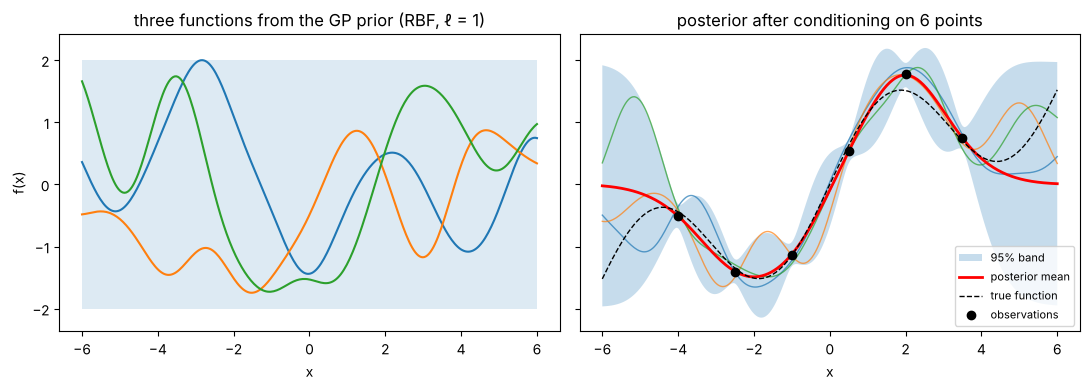

x =  0.50: posterior mean +0.538, sd 0.099   (prior sd 1.0)
x =  1.26: posterior mean +1.402, sd 0.344   (prior sd 1.0)
x =  5.52: posterior mean +0.033, sd 0.991   (prior sd 1.0)

max |mean - sklearn| = 4.44e-16   max |sd - sklearn| = 1.90e-15


In [20]:
def rbf(a, b, ell=1.0, sf=1.0):
    return sf**2 * np.exp(-(a[:, None] - b[None, :])**2 / (2 * ell**2))

f_true = lambda x: np.sin(x) + 0.3 * x
X_tr = np.array([-4.0, -2.5, -1.0, 0.5, 2.0, 3.5])
y_tr = f_true(X_tr) + rng.normal(0, 0.1, len(X_tr))
xs = np.linspace(-6, 6, 300)
ell, sf, sn2 = 1.0, 1.0, 0.01

K = rbf(X_tr, X_tr, ell, sf) + sn2 * np.eye(len(X_tr))        # K + sigma_n^2 I
Ks = rbf(X_tr, xs, ell, sf)                                    # k_* for every test point (columns)
Kss = rbf(xs, xs, ell, sf)
alpha = np.linalg.solve(K, y_tr)
post_mean = Ks.T @ alpha                                       # Sigma_12 Sigma_22^{-1} (y - 0)
post_cov = Kss - Ks.T @ np.linalg.solve(K, Ks)                 # Schur complement
post_sd = np.sqrt(np.clip(np.diag(post_cov), 0, None))

jitter = 1e-8 * np.eye(len(xs))
prior_samples = np.linalg.cholesky(Kss + jitter) @ rng.standard_normal((len(xs), 3))
post_samples = post_mean[:, None] + np.linalg.cholesky(post_cov + jitter) @ rng.standard_normal((len(xs), 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax1.plot(xs, prior_samples, lw=1.5); ax1.fill_between(xs, -2*sf, 2*sf, alpha=0.15)
ax1.set_title("three functions from the GP prior (RBF, ℓ = 1)"); ax1.set_xlabel("x"); ax1.set_ylabel("f(x)")
ax2.fill_between(xs, post_mean - 1.96*post_sd, post_mean + 1.96*post_sd, alpha=0.25, label="95% band")
ax2.plot(xs, post_samples, lw=1, alpha=0.7)
ax2.plot(xs, post_mean, "r", lw=2, label="posterior mean")
ax2.plot(xs, f_true(xs), "k--", lw=1, label="true function")
ax2.plot(X_tr, y_tr, "ko", label="observations")
ax2.set_title("posterior after conditioning on 6 points"); ax2.set_xlabel("x"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

for xq in (0.5, 1.25, 5.5):
    i = np.argmin(np.abs(xs - xq))
    print(f"x = {xs[i]:5.2f}: posterior mean {post_mean[i]:+.3f}, sd {post_sd[i]:.3f}   (prior sd {sf:.1f})")

# the same posterior from scikit-learn (no hyperparameter optimisation, so the kernels match exactly)
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
gpr = GaussianProcessRegressor(kernel=ConstantKernel(sf**2, "fixed") * RBF(ell, "fixed"), alpha=sn2, optimizer=None).fit(X_tr[:, None], y_tr)
sk_mean, sk_sd = gpr.predict(xs[:, None], return_std=True)
print(f"\nmax |mean - sklearn| = {np.abs(post_mean - sk_mean).max():.2e}   max |sd - sklearn| = {np.abs(post_sd - sk_sd).max():.2e}")

Near the observations the posterior standard deviation collapses to about $0.1$ (the noise level); between
them it grows, and beyond $x = 4$ it returns to the prior value $1$ — the band widens exactly where there is
no data, which is what makes Gaussian processes useful for deciding where to measure next. The posterior
samples are plausible functions consistent with the data, not just a mean curve. Our thirty lines agree with
`GaussianProcessRegressor` to machine precision: the library is the conditioning formula plus a Cholesky solve.

## 9. Dependence beyond Gaussians: copulas and mutual information

Two pairs with *identical* standard-normal marginals and nearly identical correlation, one tied together by
a Gaussian copula and one by a $t_3$-copula. Then a histogram estimate of mutual information
$I(X; Y) = \sum p(x, y)\log_2\frac{p(x, y)}{p(x)p(y)}$ for the zero-correlation pair $Y = X^2$.

Pearson correlation:  Gaussian copula 0.503   t copula 0.495
Spearman correlation: Gaussian copula 0.485   t copula 0.470

P(asset 2 below its q-quantile | asset 1 below its q-quantile):   [simulated / exact]
  q =  5.0%:  Gaussian copula 0.253 / 0.244     t copula 0.382 / 0.365     (independence: 0.050)
  q =  1.0%:  Gaussian copula 0.146 / 0.129     t copula 0.369 / 0.327     (independence: 0.010)
  q =  0.1%:  Gaussian copula 0.060 / 0.054     t copula 0.380 / 0.336     (independence: 0.001)
as q -> 0 the Gaussian conditional probability goes to 0 (no tail dependence); the t copula's tends to a positive limit


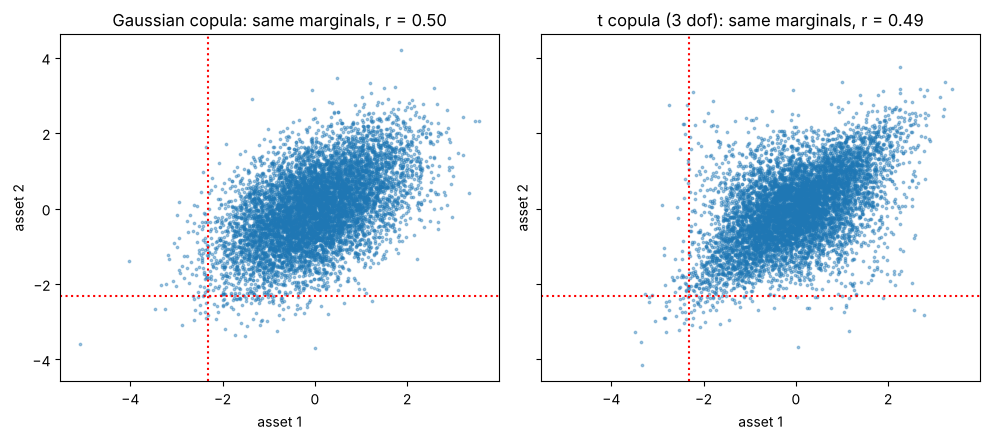

independent N(0,1)     correlation = -0.002   mutual information ~ 0.010 bits
Gaussian, rho = 0.707  correlation = +0.706   mutual information ~ 0.494 bits
Y = X^2                correlation = +0.002   mutual information ~ 1.671 bits
exact MI for a Gaussian with rho = 0.707: -0.5 log2(1 - 0.5) = 0.5 bits;  for Y = X^2 it is unbounded (Y is a function of X)


In [21]:
n, rho, nu = 100_000, 0.5, 3
Lc = np.linalg.cholesky(np.array([[1.0, rho], [rho, 1.0]]))
zg = rng.standard_normal((n, 2)) @ Lc.T                        # bivariate normal with correlation rho
u_gauss = stats.norm.cdf(zg)                                   # Gaussian copula: uniform marginals
zt = zg / np.sqrt(rng.chisquare(nu, n) / nu)[:, None]         # bivariate t_3 with the same rho
u_t = stats.t.cdf(zt, nu)                                      # t copula
x_gauss, x_t = stats.norm.ppf(u_gauss), stats.norm.ppf(u_t)    # both get standard-normal marginals

print(f"Pearson correlation:  Gaussian copula {np.corrcoef(x_gauss.T)[0, 1]:.3f}   t copula {np.corrcoef(x_t.T)[0, 1]:.3f}")
print(f"Spearman correlation: Gaussian copula {stats.spearmanr(x_gauss)[0]:.3f}   t copula {stats.spearmanr(x_t)[0]:.3f}")
mvn_ref = stats.multivariate_normal([0, 0], [[1, rho], [rho, 1]]); mvt_ref = stats.multivariate_t([0, 0], [[1, rho], [rho, 1]], df=nu)
print("\nP(asset 2 below its q-quantile | asset 1 below its q-quantile):   [simulated / exact]")
for qtl in (0.05, 0.01, 0.001):
    sim_g = ((u_gauss[:, 0] < qtl) & (u_gauss[:, 1] < qtl)).mean() / qtl
    sim_t = ((u_t[:, 0] < qtl) & (u_t[:, 1] < qtl)).mean() / qtl
    ex_g = mvn_ref.cdf([stats.norm.ppf(qtl)] * 2) / qtl
    ex_t = mvt_ref.cdf([stats.t.ppf(qtl, nu)] * 2) / qtl
    print(f"  q = {qtl:5.1%}:  Gaussian copula {sim_g:.3f} / {ex_g:.3f}     t copula {sim_t:.3f} / {ex_t:.3f}     (independence: {qtl:.3f})")
print("as q -> 0 the Gaussian conditional probability goes to 0 (no tail dependence); the t copula's tends to a positive limit")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, data, name in zip(axes, (x_gauss, x_t), ("Gaussian copula", "t copula (3 dof)")):
    ax.scatter(data[:8000, 0], data[:8000, 1], s=3, alpha=0.4)
    ax.axvline(stats.norm.ppf(0.01), color="r", ls=":"); ax.axhline(stats.norm.ppf(0.01), color="r", ls=":")
    ax.set_title(f"{name}: same marginals, r = {np.corrcoef(data.T)[0, 1]:.2f}"); ax.set_xlabel("asset 1"); ax.set_ylabel("asset 2")
plt.tight_layout(); plt.show()

def mutual_info_hist(x, y, bins=30):
    H, _, _ = np.histogram2d(x, y, bins=bins); p = H / H.sum()
    px, py = p.sum(axis=1, keepdims=True), p.sum(axis=0, keepdims=True)
    nz = p > 0
    return float((p[nz] * np.log2(p[nz] / (px @ py)[nz])).sum())

x = rng.standard_normal(50_000)
for name, y in (("independent N(0,1)", rng.standard_normal(50_000)),
                ("Gaussian, rho = 0.707", 0.707*x + 0.707*rng.standard_normal(50_000)),
                ("Y = X^2", x**2)):
    print(f"{name:22s} correlation = {np.corrcoef(x, y)[0, 1]:+.3f}   mutual information ~ {mutual_info_hist(x, y):.3f} bits")
print("exact MI for a Gaussian with rho = 0.707: -0.5 log2(1 - 0.5) = 0.5 bits;  for Y = X^2 it is unbounded (Y is a function of X)")

The two scatter plots have the same marginals and nearly the same correlation, yet joint extremes (both
below the red lines) are clearly more common under the $t$-copula. The conditional probability "asset 2
crashes given that asset 1 crashed" tells the story: under the Gaussian copula it *falls* as the threshold
moves further into the tail (towards zero — no tail dependence), while under the $t$-copula it stays around
a third no matter how extreme the event (the exact column is the one to trust at $q = 0.1\%$, where the
simulation rests on only about a hundred joint events). At the 0.1% level the joint crash is already about
five to six times more likely. No univariate check and no correlation matrix would detect the difference — this is the mechanism
behind the 2008 mispricing described in the guide. Mutual
information, by contrast, sees what correlation misses: it is about $0$ for the independent pair, close to the
exact $0.5$ bits for the $\rho = 0.707$ Gaussian (the histogram estimate is slightly biased upwards), and large
for $Y = X^2$ despite its zero correlation.

## Summary

- A joint table contains everything: marginals are axis sums, conditionals are renormalised rows, independence is "the table is the outer product of its marginals" (rank 1).
- Covariance measures linear co-movement and depends on units; correlation is its unit-free version in $[-1, 1]$; zero correlation does not mean independence ($Y = X^2$).
- The covariance matrix is symmetric positive semidefinite because $a^\top \Sigma a = \operatorname{Var}(a^\top X) \ge 0$; linear maps act by $A \Sigma A^\top$; the sample version is $\mathbf{X}_c^\top \mathbf{X}_c/(n-1)$ and whitening by $\Sigma^{-1/2}$ decorrelates.
- The multivariate Gaussian has ellipsoidal level sets with axes from the eigendecomposition of $\Sigma$, is sampled as $\mu + Lz$ with $LL^\top = \Sigma$, and its squared Mahalanobis distance is $\chi^2_d$.
- Conditioning a Gaussian shifts the mean linearly in the observation and shrinks the covariance by the Schur complement — independently of the observed value; regression slopes multiply to $\rho^2$.
- $\mathbb{E}[Y \mid X]$ is the best MSE predictor and the target of every regressor; $\operatorname{Var} Y$ = within + between.
- Simpson's paradox: differing stratum mixes can reverse an aggregate comparison; standardise or randomise, but decide causally which table to trust.
- The Kalman filter and Gaussian-process regression are the conditioning formula applied over time and over space; both matched reference implementations exactly.
- Copulas separate marginals from dependence; tail dependence and mutual information capture what correlation cannot.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.